In [1]:
# Core data handling libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and evaluation from scikit learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline                          # chaining preprocessing steps together
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, precision_recall_curve,
                              f1_score)                          # evaluation metrics (model check karne ke liye)
from sklearn.utils import class_weight                          # for handling class imbalance

# Deep learning libraries
import tensorflow as tf                          # main deep learning framework
from tensorflow import keras                     # high level API of TensorFlow
from tensorflow.keras import layers               # building blocks of neural network

# Reproducibility
import random
SEED = 42                                          # fixed seed so results are reproducible (same result har dafa aaye)
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)       # confirming TensorFlow is loaded correctly
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)   # check karte hain GPU available hai ya nahi


TensorFlow version: 2.20.0
GPU Available: True


In [3]:
df = pd.read_csv("adult.csv")

print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


### Handling Missing Values
From `df.head()` and `df.info()`, we observed that some columns contain '?' as missing values. I will replace these with `np.nan` and then check for missing values.

In [23]:
df.replace('?', np.nan, inplace=True)

# Check for missing values after replacement
missing_values = df.isnull().sum()

missing_df = pd.DataFrame({'Missing Count': missing_values})

print('Missing values in each column:')
print(missing_df[missing_df['Missing Count'] > 0])



Missing values in each column:
        Missing Count
income          32561


### Target Variable Analysis: Income
Let's analyze the distribution of the `income` column, as it appears to be the target variable, to check for class imbalance.

Income distribution:
income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64


/tmp/ipykernel_1186/3389628741.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=income_distribution.index, y=income_distribution.values, palette='viridis')


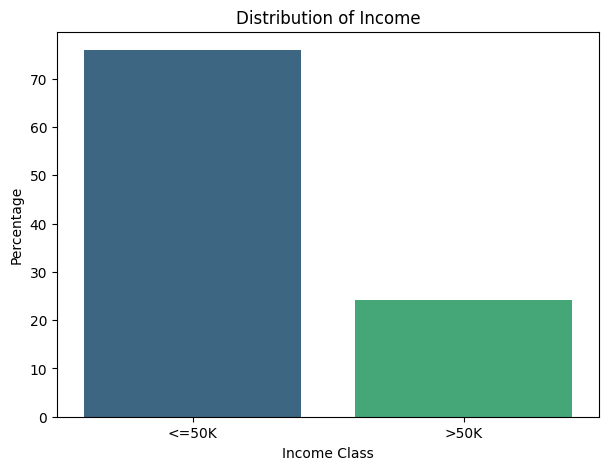

In [8]:
income_distribution = df['income'].value_counts(normalize=True) * 100
print('Income distribution:')
print(income_distribution)

plt.figure(figsize=(7, 5))
sns.barplot(x=income_distribution.index, y=income_distribution.values, palette='viridis')
plt.title('Distribution of Income')
plt.xlabel('Income Class')
plt.ylabel('Percentage')
plt.show()

In [9]:
# Impute missing categorical values with the mode
for col in ['workclass', 'occupation', 'native.country']:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f"Missing values in '{col}' imputed with mode: {mode_val}")

# Verify that there are no more missing values in these columns
print("\nMissing values after imputation:")
print(df[['workclass', 'occupation', 'native.country']].isnull().sum())

Missing values in 'workclass' imputed with mode: Private
Missing values in 'occupation' imputed with mode: Prof-specialty
Missing values in 'native.country' imputed with mode: United-States

Missing values after imputation:
workclass         0
occupation        0
native.country    0
dtype: int64


/tmp/ipykernel_1186/2652079183.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mode_val, inplace=True)


In [10]:
categorical_features = df.select_dtypes(include='object').columns.tolist()
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Remove 'income' from categorical_features as it's the target variable
if 'income' in categorical_features:
    categorical_features.remove('income')

print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")
print(f"Numerical Features ({len(numerical_features)}): {numerical_features}")

Categorical Features (8): ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
Numerical Features (6): ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']


In [15]:
# Display descriptive statistics for numerical features
print("Descriptive statistics for numerical features:")
print(df[numerical_features].describe().T)





Descriptive statistics for numerical features:
                  count           mean            std      min       25%  \
age             32561.0      38.581647      13.640433     17.0      28.0   
fnlwgt          32561.0  189778.366512  105549.977697  12285.0  117827.0   
education.num   32561.0      10.080679       2.572720      1.0       9.0   
capital.gain    32561.0    1077.648844    7385.292085      0.0       0.0   
capital.loss    32561.0      87.303830     402.960219      0.0       0.0   
hours.per.week  32561.0      40.437456      12.347429      1.0      40.0   

                     50%       75%        max  
age                 37.0      48.0       90.0  
fnlwgt          178356.0  237051.0  1484705.0  
education.num       10.0      12.0       16.0  
capital.gain         0.0       0.0    99999.0  
capital.loss         0.0       0.0     4356.0  
hours.per.week      40.0      45.0       99.0  


In [26]:
# Reload the dataset to ensure 'income' column is in original string format
df = pd.read_csv("adult.csv")

# Replace '?' with np.nan for consistency in missing value handling
df.replace('?', np.nan, inplace=True)

# Impute missing categorical values again (as df was reloaded)
for col in ['workclass', 'occupation', 'native.country']:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)

# Correctly encode the target column 'income' into 0 and 1
# '>50K' will be 1, '<=50K' will be 0
df['income'] = df['income'].map({'>50K': 1, '<=50K': 0})

# Separating features (X) and target (y)
X = df.drop(columns=['income'])
y = df['income']



/tmp/ipykernel_1186/868909047.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mode_val, inplace=True)


In [25]:
# Splitting into train and temp (temp will become validation and test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)      # stratify ensures class ratios are maintained in splits

# Splitting temp into validation and test, equal halves
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f"Train set size: X={X_train.shape}, y={y_train.shape}")
print(f"Validation set size: X={X_val.shape}, y={y_val.shape}")
print(f"Test set size: X={X_test.shape}, y={y_test.shape}")

Train set size: X=(22792, 14), y=(22792,)
Validation set size: X=(4884, 14), y=(4884,)
Test set size: X=(4885, 14), y=(4885,)


In [27]:
# Building preprocessing pipeline for mixed data types
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_features),                       # scaling numeric columns (numeric ko scale karna)
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)  # encoding categorical columns (category ko number mein badalna)
])

# Fitting only on training data, then transforming all three sets
X_train_processed = preprocessor.fit_transform(X_train)     # fit and transform on train only (sirf train par fit karna)
X_val_processed = preprocessor.transform(X_val)               # transform validation using train statistics
X_test_processed = preprocessor.transform(X_test)             # transform test using train statistics

print("Processed training shape:", X_train_processed.shape)


Processed training shape: (22792, 104)


In [28]:
# Computing class weights to handle imbalance
weights = class_weight.compute_class_weight(
    class_weight='balanced', classes=np.unique(y_train), y=y_train)   # automatically balancing weight by class frequency
class_weights = {0: weights[0], 1: weights[1]}                         # dictionary format required by Keras

print("Class weights:", class_weights)


Class weights: {0: np.float64(0.6586141131595677), 1: np.float64(2.0761523046092183)}


In [29]:
# Defining input dimension based on processed features
input_dim = X_train_processed.shape[1]                # number of input features after preprocessing

def build_model(input_dim):
    model = keras.Sequential([                          # sequential stack of layers
        layers.Input(shape=(input_dim,)),                # input layer matching feature count
        layers.Dense(64, activation='relu'),              # first hidden layer, 64 neurons
        layers.BatchNormalization(),                       # normalizing activations for stable training
        layers.Dropout(0.3),                                # dropping 30 percent neurons to reduce overfitting

        layers.Dense(32, activation='relu'),               # second hidden layer, 32 neurons
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(16, activation='relu'),               # third hidden layer, 16 neurons
        layers.Dropout(0.2),

        layers.Dense(1, activation='sigmoid')               # output layer, single neuron for binary classification
    ])
    return model

model = build_model(input_dim)
model.summary()                                            # printing architecture summary (model ka structure dekhna)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,729 (38.00 KB)

 Trainable params: 9,537 (37.25 KB)

 Non-trainable params: 192 (768.00 B)

In [30]:
# Compiling the model with loss, optimizer and metrics
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),     # Adam optimizer with a sensible default learning rate
    loss='binary_crossentropy',                                 # correct loss for binary classification
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),           # overall accuracy
        keras.metrics.Precision(name='precision'),                # precision on positive class
        keras.metrics.Recall(name='recall'),                       # recall on positive class
        keras.metrics.AUC(name='auc')                               # area under ROC curve
    ]
)


In [31]:
# Setting up training callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True),   # stop early if no improvement (improvement na ho to rukna)
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),       # reduce learning rate on plateau
    keras.callbacks.ModelCheckpoint(
        'best_model.keras', monitor='val_loss', save_best_only=True)    # save only the best model version
]

# Training the model
history = model.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,                                    # upper limit, early stopping will likely stop sooner
    batch_size=32,
    class_weight=class_weights,                     # applying class weights computed earlier
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
713/713 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.7156 - auc: 0.8267 - loss: 0.5141 - precision: 0.4502 - recall: 0.8189 - val_accuracy: 0.7903 - val_auc: 0.9010 - val_loss: 0.3875 - val_precision: 0.5404 - val_recall: 0.8639 - learning_rate: 0.0010
Epoch 2/100
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7809 - auc: 0.8855 - loss: 0.4216 - precision: 0.5278 - recall: 0.8548 - val_accuracy: 0.8034 - val_auc: 0.9030 - val_loss: 0.3794 - val_precision: 0.5606 - val_recall: 0.8495 - learning_rate: 0.0010
Epoch 3/100
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7916 - auc: 0.8930 - loss: 0.4079 - precision: 0.5425 - recall: 0.8608 - val_accuracy: 0.8034 - val_auc: 0.9049 - val_loss: 0.3814 - val_precision: 0.5597 - val_recall: 0.8614 - learning_rate: 0.0010
Epoch 4/100
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7988 - auc: 0.8989 - loss: 0.3980 - precision: 0.5526 - recall: 0.8643 - val_accuracy: 0.8047 - val_auc: 0.9054 - val_loss: 0.3773

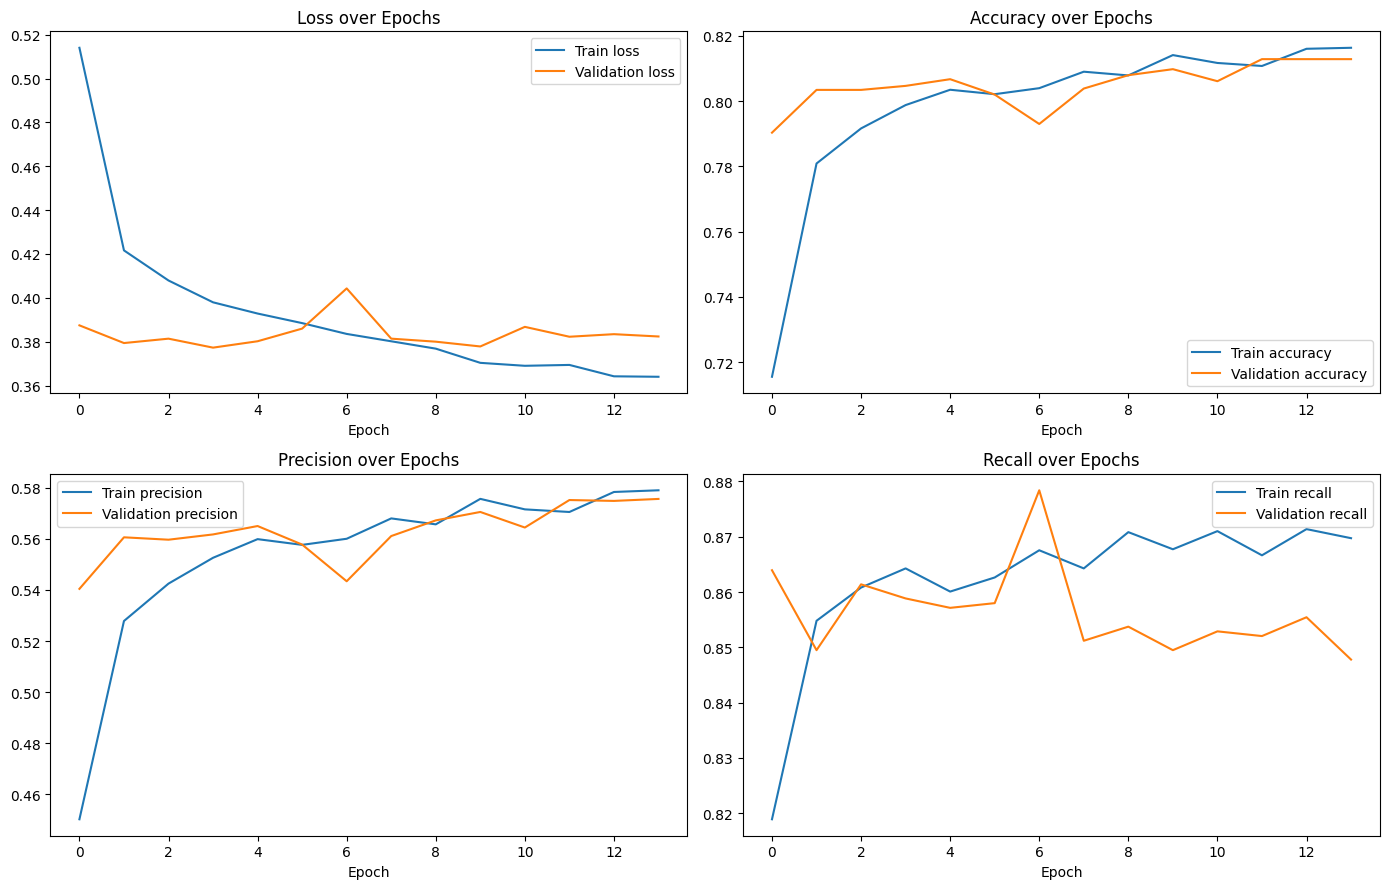

In [32]:
# Plotting loss and key metrics across epochs
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

metrics_to_plot = ['loss', 'accuracy', 'precision', 'recall']
for ax, metric in zip(axes.flatten(), metrics_to_plot):
    ax.plot(history.history[metric], label=f'Train {metric}')            # training curve
    ax.plot(history.history[f'val_{metric}'], label=f'Validation {metric}')  # validation curve
    ax.set_title(f'{metric.capitalize()} over Epochs')
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.show()


In [41]:
# Generating predictions on the test set
y_pred_prob = model.predict(X_test_processed).flatten()   # predicted probabilities (probability values)
y_pred = (y_pred_prob >= 0.5).astype(int)                    # converting probability into class label using 0.5 threshold

# Printing full classification report
print(classification_report(y_test, y_pred, target_names=['Income Lower than 50K', 'Income Higher than 50K']))

# ROC AUC score
auc_score = roc_auc_score(y_test, y_pred_prob)
print(f"Test ROC AUC Score: {auc_score:.4f}")

153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
                        precision    recall  f1-score   support

 Income Lower than 50K       0.95      0.78      0.86      3709
Income Higher than 50K       0.56      0.86      0.67      1176

              accuracy                           0.80      4885
             macro avg       0.75      0.82      0.77      4885
          weighted avg       0.85      0.80      0.81      4885

Test ROC AUC Score: 0.9046


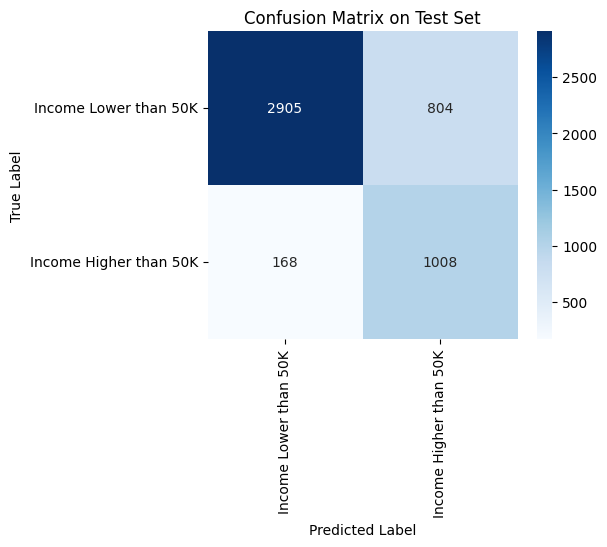

In [42]:
# Plotting confusion matrix
cm = confusion_matrix(y_test, y_pred)                       # computing confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Income Lower than 50K', 'Income Higher than 50K'], yticklabels=['Income Lower than 50K', 'Income Higher than 50K'])
plt.title('Confusion Matrix on Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

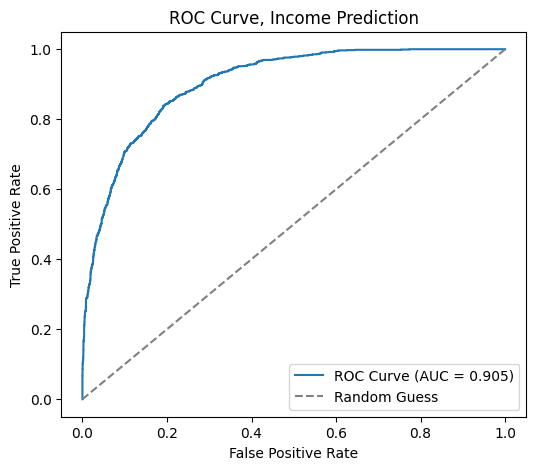

In [43]:
# Plotting ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)                # false positive and true positive rates
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve, Income Prediction')
plt.legend()
plt.show()

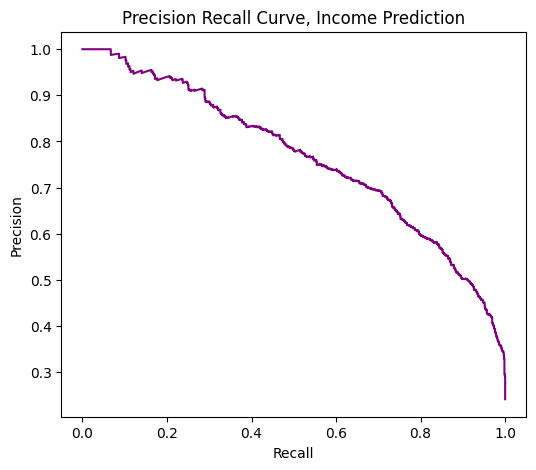

In [37]:
# Plotting Precision Recall curve, useful for imbalanced problems
precision_vals, recall_vals, thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure(figsize=(6, 5))
plt.plot(recall_vals, precision_vals, color='purple')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision Recall Curve, Income Prediction')
plt.show()


In [44]:
# Finding the threshold that gives the best F1 score
best_f1 = 0
best_threshold = 0.5
for t in np.arange(0.1, 0.9, 0.01):                          # scanning thresholds from 0.1 to 0.9
    preds_t = (y_pred_prob >= t).astype(int)
    f1 = f1_score(y_test, preds_t)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

print(f"Best threshold: {best_threshold:.2f}, F1 score: {best_f1:.4f}")

# Comparing default threshold vs tuned threshold
y_pred_tuned = (y_pred_prob >= best_threshold).astype(int)
print("\nClassification report with tuned threshold:")
print(classification_report(y_test, y_pred_tuned, target_names=['Income Lower than 50K', 'Income Higher than 50K']))

Best threshold: 0.65, F1 score: 0.6993

Classification report with tuned threshold:
                        precision    recall  f1-score   support

 Income Lower than 50K       0.91      0.89      0.90      3709
Income Higher than 50K       0.67      0.73      0.70      1176

              accuracy                           0.85      4885
             macro avg       0.79      0.81      0.80      4885
          weighted avg       0.85      0.85      0.85      4885



/tmp/ipykernel_1186/2098011589.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, y='feature', x='importance', palette='viridis')


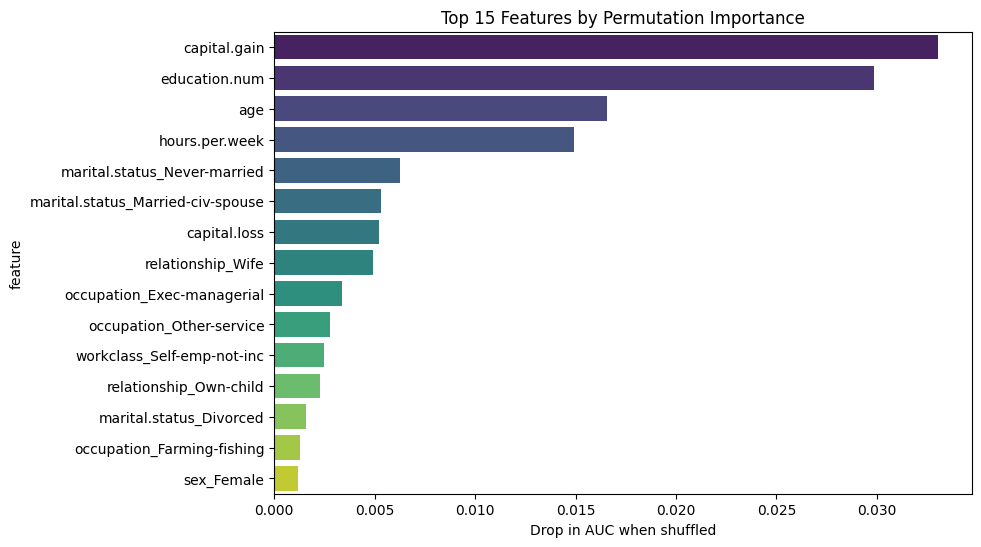

In [39]:
# Computing permutation importance manually for the neural network
def permutation_importance_nn(model, X, y_true, baseline_auc, feature_names, n_repeats=3):
    importances = []
    X_array = X.toarray() if hasattr(X, 'toarray') else np.array(X)   # handling sparse matrix output from OneHotEncoder

    for i in range(X_array.shape[1]):
        scores = []
        for _ in range(n_repeats):
            X_permuted = X_array.copy()
            np.random.shuffle(X_permuted[:, i])                        # shuffling one feature column at a time
            preds = model.predict(X_permuted, verbose=0).flatten()
            score = roc_auc_score(y_true, preds)
            scores.append(baseline_auc - score)                         # drop in AUC after shuffling
        importances.append(np.mean(scores))
    return importances

# Getting feature names after one hot encoding
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(ohe_feature_names)          # combining numeric and encoded categorical names

# Running permutation importance, limited to a subset for speed in classroom demo
importances = permutation_importance_nn(model, X_test_processed, y_test, auc_score, all_feature_names, n_repeats=2)

importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).head(15)                  # top 15 most important features

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, y='feature', x='importance', palette='viridis')
plt.title('Top 15 Features by Permutation Importance')
plt.xlabel('Drop in AUC when shuffled')
plt.show()


In [45]:
def predict_income(raw_customer_df, model, preprocessor, threshold=best_threshold):

    processed = preprocessor.transform(raw_customer_df)          # applying same transformation as training
    probabilities = model.predict(processed, verbose=0).flatten()   # getting churn probability
    labels = (probabilities >= threshold).astype(int)              # converting to final label using tuned threshold

    results = raw_customer_df.copy()
    results['probability'] = probabilities
    results['prediction'] = np.where(labels == 1, 'Income Higher than 50K', 'Income Lower than 50K')
    return results

# Demonstrating inference on a small sample from the test set
sample_customers = X_test.iloc[:5]                              # taking 5 raw sample rows
prediction_output = predict_income(sample_customers, model, preprocessor)
prediction_output[['capital.gain', 'education.num', 'age', 'probability', 'prediction']]

,capital.gain,education.num,age,probability,prediction
16402,0,9,20,0.121997,Income Lower than 50K
21837,0,7,17,0.001014,Income Lower than 50K
9208,0,7,30,0.128186,Income Lower than 50K
8996,0,10,28,0.011429,Income Lower than 50K
8782,0,10,42,0.085451,Income Lower than 50K
